# 00 · vLLM smoke test (vision)

Starts the vLLM container from `compose.yaml` (options in `vllm/serve.yaml`) and checks that Qwen3.8-27B is serving **with vision**.

Only one vLLM fits on the RTX 3090: stop `skyrag-vllm` / `aviation-vllm*` first. Start it from a terminal in the repo root:

```bash
docker compose up -d && docker compose logs -f vllm   # ~2.5 min to healthy
docker compose down                                    # when done
```

**Speculative decoding is off on purpose.** With n-gram speculation this hybrid model produced corrupted greedy output (unclosed bold, misplaced phrases; fidelity 0.97 instead of 1.0). See the comment in `vllm/serve.yaml`.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # all paths below are relative to the repo root
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
PDF = ROOT / "cs-e_amendment_9.pdf"   # header/footer already cropped
DATA = ROOT / "data"

In [2]:
import time, urllib.request
from openai import OpenAI

base = os.environ["VLLM_ENDPOINT"]
health = base.rsplit("/v1", 1)[0] + "/health"

def wait_healthy(timeout_s=600):
    t0 = time.time()
    while time.time() - t0 < timeout_s:
        try:
            urllib.request.urlopen(health, timeout=5)
            return round(time.time() - t0)
        except Exception:
            time.sleep(10)
    raise TimeoutError(f"{health} not healthy after {timeout_s}s; check `docker compose logs vllm`")

print("healthy after", wait_healthy(), "s")
client = OpenAI(base_url=base, api_key=os.environ.get("VLLM_API_KEY", "EMPTY"))
print([m.id for m in client.models.list().data])

healthy after 0 s
['RedHatAI/Qwen3.8-27B-INT4']


## One real request: CS-E 15, page 17

The page region is rendered at 150 DPI and sent together with the region's text from the PDF text layer (the *grounded* prompt from `csparse.vlm`).

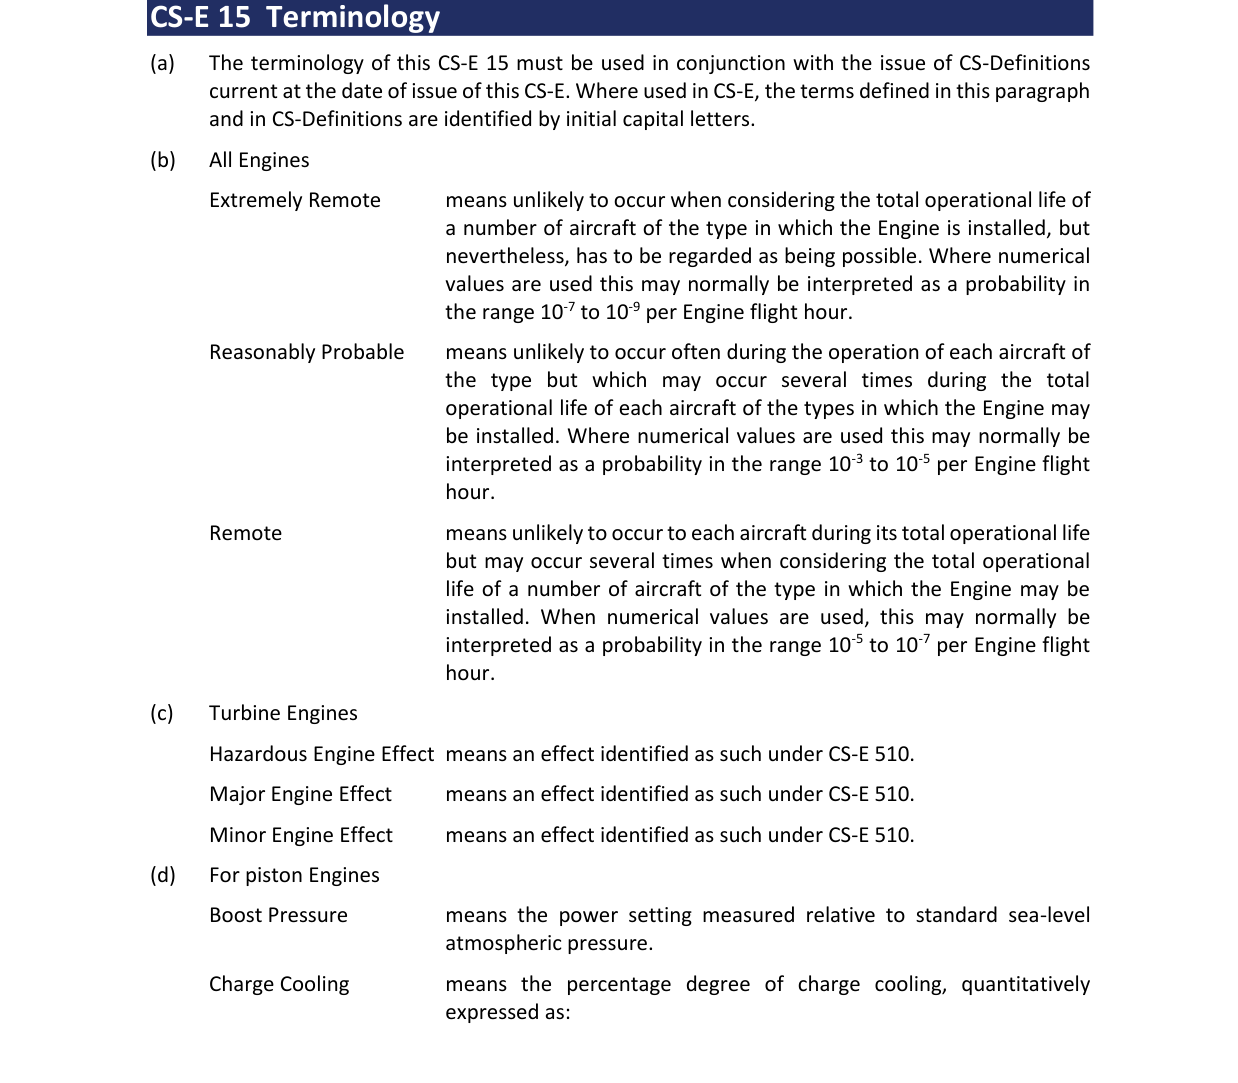

In [3]:
import pymupdf
from IPython.display import Image, Markdown, display
from csparse.segment import build_sections, region_png, region_text
from csparse.vlm import Extractor, VLMConfig, build_messages, clean_output, fidelity, strip_heading

doc = pymupdf.open(PDF)
sec = {s.section_id: s for s in build_sections(doc)}["CS-E 15"]
region = sec.regions[0]
png = region_png(doc, region, dpi=150)
source = strip_heading(region_text(doc, region), sec.title)
display(Image(png, width=500))

In [4]:
ex = Extractor(PDF, VLMConfig())
raw, info = ex.call(build_messages(png, source, sec, 0, prev_tail=None))
md = clean_output(raw)
m = fidelity(source, md)
print(info)
print(f"{info['completion_tokens'] / info['seconds']:.1f} output tok/s (incl. prefill)")
print({k: m[k] for k in ("recall", "precision", "missing", "extra")})
display(Markdown(md))

{'seconds': 28.3, 'finish_reason': 'stop', 'prompt_tokens': 2412, 'completion_tokens': 410}
14.5 output tok/s (incl. prefill)
{'recall': 1.0, 'precision': 1.0, 'missing': [], 'extra': []}


(a) The terminology of this CS-E 15 must be used in conjunction with the issue of CS-Definitions current at the date of issue of this CS-E. Where used in CS-E, the terms defined in this paragraph and in CS-Definitions are identified by initial capital letters.
(b) All Engines
- **Extremely Remote**: means unlikely to occur when considering the total operational life of a number of aircraft of the type in which the Engine is installed, but nevertheless, has to be regarded as being possible. Where numerical values are used this may normally be interpreted as a probability in the range 10^-7 to 10^-9 per Engine flight hour.
- **Reasonably Probable**: means unlikely to occur often during the operation of each aircraft of the type but which may occur several times during the total operational life of each aircraft of the types in which the Engine may be installed. Where numerical values are used this may normally be interpreted as a probability in the range 10^-3 to 10^-5 per Engine flight hour.
- **Remote**: means unlikely to occur to each aircraft during its total operational life but may occur several times when considering the total operational life of a number of aircraft of the type in which the Engine may be installed. When numerical values are used, this may normally be interpreted as a probability in the range 10^-5 to 10^-7 per Engine flight hour.
(c) Turbine Engines
- **Hazardous Engine Effect**: means an effect identified as such under CS-E 510.
- **Major Engine Effect**: means an effect identified as such under CS-E 510.
- **Minor Engine Effect**: means an effect identified as such under CS-E 510.
(d) For piston Engines
- **Boost Pressure**: means the power setting measured relative to standard sea-level atmospheric pressure.
- **Charge Cooling**: means the percentage degree of charge cooling, quantitatively expressed as: